# 04 Modeling (dev set, 5-fold cross-validation)

**Input:** `data/processed/features.parquet`, dev rows only (set-a + set-b). The test set (set-c) is not used here; it is scored once in Phase 5.
**Folds:** the 5 stratified folds saved in notebook 01.

## Models
| Model | Missing values | Imbalance | Tuned (inner 3-fold CV) |
|---|---|---|---|
| SAPS-I, SOFA (raw score) | rows without a score are left out | none | nothing to tune |
| SAPS-I recalibrated | same | none | one-feature logistic regression, gives a probability |
| Logistic regression, unweighted | median impute + `has_` flags | none | C (L2 strength) |
| Logistic regression, balanced | same | class_weight="balanced" | C |
| Random forest | native NaN support | class_weight="balanced_subsample" | min_samples_leaf, max_features |
| LightGBM | native NaN support | none | num_leaves, min_child_samples; early stopping inside the training fold |

## Nested cross-validation
For each outer fold k: a grid search with 3 inner folds runs on the other 4 folds only, picks the hyperparameters, refits, and predicts fold k. Every stay therefore gets exactly one **out-of-fold (OOF)** prediction from a model that never saw it, and the hyperparameter choice never saw it either.

## Selection rule (fixed before looking at the results)
Best pooled OOF **AUPRC**, AUROC as the tie-break. If a simpler model is not significantly worse in AUPRC than the best (paired bootstrap 95% CI of the difference includes 0), choose the simpler one. Simplicity order: logistic regression (unweighted, then balanced) < random forest < LightGBM.

In [1]:
# ── Cell 1: setup, dev set, exclude empty stays ─────────────────────
# INSIGHTS
# - Decision (Phase 3): stays with no measurements at all are excluded from training
#   and evaluation and reported separately.
# - Result: 10 dev stays excluded (no measurements, 0 deaths). Modeling set: 7,990 stays,
#   1,122 deaths (14.04%), 225 features. 7,648 stays (95.7%) have a SAPS-I score.
#   The 5 folds have 1,597 to 1,599 stays each, 14.0% to 14.1% mortality.
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import models as M

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

table = pd.read_parquet(PROCESSED / "features.parquet")
dev_all = table[table["split"] == "dev"]
del table  # the test rows are not used in this notebook

empty = M.empty_stay_mask(dev_all)
print(f"Dev stays: {len(dev_all):,}. Excluded (no measurements): {empty.sum()}, "
      f"deaths among them: {dev_all.loc[empty, M.LABEL].sum()}")
dev = dev_all[~empty].reset_index(drop=True)

FEATURES = M.feature_columns(dev)
X, y, folds = dev[FEATURES], dev[M.LABEL], dev["fold"]
has_saps = dev["SAPS-I"].notna()
print(f"Modeling set: {len(dev):,} stays, {y.sum()} deaths ({y.mean():.2%}), {len(FEATURES)} features")
print(f"Stays with a SAPS-I score: {has_saps.sum():,} ({has_saps.mean():.1%})")
display(dev.groupby("fold")[M.LABEL].agg(stays="size", mortality="mean").round(4))

OOF = {}       # model name -> out-of-fold probabilities (or scores)
PER_FOLD = {}  # model name -> per-fold table

Dev stays: 8,000. Excluded (no measurements): 10, deaths among them: 0
Modeling set: 7,990 stays, 1122 deaths (14.04%), 225 features
Stays with a SAPS-I score: 7,648 (95.7%)


,stays,mortality
fold,,
0,1599,0.1401
1,1598,0.1402
2,1597,0.1403
3,1598,0.1408
4,1598,0.1408


In [2]:
# ── Cell 2: baselines (SAPS-I, SOFA, SAPS-I recalibrated) ───────────
# INSIGHTS
# - The raw score is a ranking, so AUROC/AUPRC need no fitting. It is not a probability,
#   so it has no Brier score.
# - "SAPS-I recalibrated" = logistic regression with SAPS-I as the only input, fitted on
#   the training folds. Same ranking (same AUROC) but it outputs a probability, which we
#   need for calibration comparisons.
# - Result: SAPS-I AUROC 0.661 / AUPRC 0.241 (n=7,648); SOFA 0.639 / 0.256 (n=7,719);
#   SAPS-I recalibrated 0.660 / 0.245. Recalibration keeps the ranking, as expected.
for score in ["SAPS-I", "SOFA"]:
    OOF[f"{score} (raw score)"] = dev[score]

recal = pd.Series(np.nan, index=dev.index)
for k in sorted(folds.unique()):
    tr = (folds != k) & has_saps
    te = (folds == k) & has_saps
    lr = LogisticRegression().fit(dev.loc[tr, ["SAPS-I"]], y[tr])
    recal[te] = lr.predict_proba(dev.loc[te, ["SAPS-I"]])[:, 1]
OOF["SAPS-I recalibrated"] = recal

for name in ["SAPS-I (raw score)", "SOFA (raw score)", "SAPS-I recalibrated"]:
    ok = OOF[name].notna()
    print(f"{name:22s} n={ok.sum():,}  AUROC {roc_auc_score(y[ok], OOF[name][ok]):.3f}  "
          f"AUPRC {average_precision_score(y[ok], OOF[name][ok]):.3f}")

SAPS-I (raw score)     n=7,648  AUROC 0.661  AUPRC 0.241
SOFA (raw score)       n=7,719  AUROC 0.639  AUPRC 0.256
SAPS-I recalibrated    n=7,648  AUROC 0.660  AUPRC 0.245


In [3]:
# ── Cell 3: logistic regression (unweighted and balanced) ───────────
# INSIGHTS
# - Pipeline: log1p of skewed labs and counts -> median imputation -> standardise -> L2.
#   All of it is refitted inside every training fold.
# - C is the inverse regularisation strength: small C = strong penalty = simpler model.
# - Result: both versions reach AUROC about 0.867 and AUPRC about 0.55. Strong regularisation
#   is chosen (C = 0.01 or 0.03 in every fold). Fold AUPRC ranges from 0.52 to 0.60.
GRID_LR = {"model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}
for name, cw in [("LogReg (unweighted)", None), ("LogReg (balanced)", "balanced")]:
    t0 = time.time()
    OOF[name], PER_FOLD[name] = M.nested_cv(M.make_logreg(FEATURES, class_weight=cw), GRID_LR, X, y, folds)
    print(f"{name}: {time.time() - t0:.0f} s, C chosen per fold: "
          f"{[p['model__C'] for p in PER_FOLD[name]['params']]}")
    display(PER_FOLD[name][["fold", "n", "AUROC", "AUPRC"]].round(3).T)

LogReg (unweighted): 11 s, C chosen per fold: [0.01, 0.03, 0.01, 0.03, 0.03]


,0,1,2,3,4
fold,0.000,1.000,2.000,3.000,4.000
n,1599.000,1598.000,1597.000,1598.000,1598.000
AUROC,0.863,0.869,0.862,0.863,0.878
AUPRC,0.528,0.522,0.597,0.528,0.594


LogReg (balanced): 13 s, C chosen per fold: [0.01, 0.03, 0.01, 0.01, 0.01]


,0,1,2,3,4
fold,0.000,1.000,2.000,3.000,4.000
n,1599.000,1598.000,1597.000,1598.000,1598.000
AUROC,0.865,0.869,0.860,0.863,0.880
AUPRC,0.529,0.518,0.588,0.525,0.599


In [4]:
# ── Cell 4: random forest ───────────────────────────────────────────
# INSIGHTS
# - 400 trees, NaN handled natively by scikit-learn trees (no imputation needed).
# - min_samples_leaf limits how small a leaf can be (bigger = smoother, less overfit);
#   max_features is the share of features each split may look at.
# - Result: AUROC 0.847 to 0.872 per fold; usually picks min_samples_leaf 20 and 20% of
#   features per split. Clearly behind the other models (pooled AUPRC 0.494).
GRID_RF = {"min_samples_leaf": [5, 20], "max_features": ["sqrt", 0.2]}
t0 = time.time()
OOF["Random forest"], PER_FOLD["Random forest"] = M.nested_cv(M.make_rf(), GRID_RF, X, y, folds)
print(f"Random forest: {time.time() - t0:.0f} s")
print("Chosen per fold:", list(PER_FOLD["Random forest"]["params"]))
display(PER_FOLD["Random forest"][["fold", "n", "AUROC", "AUPRC"]].round(3).T)

Random forest: 72 s
Chosen per fold: [{'max_features': 0.2, 'min_samples_leaf': 20}, {'max_features': 0.2, 'min_samples_leaf': 20}, {'max_features': 0.2, 'min_samples_leaf': 20}, {'max_features': 'sqrt', 'min_samples_leaf': 5}, {'max_features': 0.2, 'min_samples_leaf': 20}]


,0,1,2,3,4
fold,0.000,1.000,2.000,3.000,4.000
n,1599.000,1598.000,1597.000,1598.000,1598.000
AUROC,0.850,0.857,0.847,0.854,0.872
AUPRC,0.487,0.477,0.539,0.513,0.548


In [5]:
# ── Cell 5: LightGBM (gradient boosting) ────────────────────────────
# INSIGHTS
# - Trees are added one at a time, each fixing the errors of the previous ones.
# - Early stopping: 15% of the TRAINING data is held aside; training stops when the
#   log loss there has not improved for 100 rounds. The scored fold is never used.
# - Fixed: learning_rate 0.03, 50% of features per tree, 80% of rows per tree.
#   Tuned: num_leaves (tree size) and min_child_samples (smallest leaf).
# - Result: AUROC 0.860 to 0.879, AUPRC 0.508 to 0.592 per fold. The smallest trees in
#   the grid (num_leaves 7, min_child_samples 20) win in every fold. That is the edge
#   of the grid, so simpler trees might do slightly better; noted as a caveat.
GRID_GBM = {"num_leaves": [7, 15, 31], "min_child_samples": [20, 50]}
t0 = time.time()
OOF["LightGBM"], PER_FOLD["LightGBM"] = M.nested_cv(M.LGBMEarlyStopping(), GRID_GBM, X, y, folds)
print(f"LightGBM: {time.time() - t0:.0f} s")
print("Chosen per fold:", list(PER_FOLD["LightGBM"]["params"]))
display(PER_FOLD["LightGBM"][["fold", "n", "AUROC", "AUPRC"]].round(3).T)

LightGBM: 39 s
Chosen per fold: [{'min_child_samples': 20, 'num_leaves': 7}, {'min_child_samples': 20, 'num_leaves': 7}, {'min_child_samples': 20, 'num_leaves': 7}, {'min_child_samples': 20, 'num_leaves': 7}, {'min_child_samples': 20, 'num_leaves': 7}]


,0,1,2,3,4
fold,0.000,1.000,2.000,3.000,4.000
n,1599.000,1598.000,1597.000,1598.000,1598.000
AUROC,0.860,0.867,0.863,0.868,0.879
AUPRC,0.508,0.536,0.592,0.549,0.572


In [6]:
# ── Cell 6: results with 95% bootstrap CIs ──────────────────────────
# INSIGHTS
# - Table A: all modeling stays (the scores cannot be computed where SAPS-I/SOFA is missing).
# - Table B: only stays with a SAPS-I score, so every row is scored on the same patients.
# - Pooled OOF = all 5 folds' predictions put together, then scored once.
# - Result: LogReg (unweighted) AUROC 0.867 [0.855, 0.877], AUPRC 0.550 [0.518, 0.581];
#   LightGBM 0.866 / 0.547; LogReg balanced 0.867 / 0.548; RF 0.850 / 0.494.
#   SAPS-I 0.661 / 0.241. Same picture on the SAPS-I subset (7,648 stays).
#   Fold-to-fold sd: AUROC about 0.007, AUPRC about 0.035, so AUPRC is the noisier metric.
def results(mask):
    rows = []
    for name, p in OOF.items():
        ok = mask & p.notna()
        s = M.summarise(y[ok], p[ok])
        rows.append({"model": name, "n": s["n"],
                     "AUROC": f"{s['AUROC']:.3f} [{s['AUROC_lo']:.3f}, {s['AUROC_hi']:.3f}]",
                     "AUPRC": f"{s['AUPRC']:.3f} [{s['AUPRC_lo']:.3f}, {s['AUPRC_hi']:.3f}]",
                     "Brier": round(s["Brier"], 4) if not np.isnan(s["Brier"]) else "-",
                     "_auprc": s["AUPRC"], "_auroc": s["AUROC"]})
    return pd.DataFrame(rows).sort_values("_auprc", ascending=False).reset_index(drop=True)

res_all = results(pd.Series(True, index=dev.index))
res_saps = results(has_saps)
print("A. All modeling stays")
display(res_all.drop(columns=["_auprc", "_auroc"]))
print("B. Stays with a SAPS-I score (like-for-like)")
display(res_saps.drop(columns=["_auprc", "_auroc"]))

fold_summary = pd.DataFrame({
    name: {"AUROC mean": t["AUROC"].mean(), "AUROC sd": t["AUROC"].std(),
           "AUPRC mean": t["AUPRC"].mean(), "AUPRC sd": t["AUPRC"].std()}
    for name, t in PER_FOLD.items()}).T.round(3)
print("Per-fold variation (5 folds)")
display(fold_summary)

A. All modeling stays


,model,n,AUROC,AUPRC,Brier
0,LogReg (unweighted),7990,"0.867 [0.855, 0.877]","0.550 [0.518, 0.581]",0.0868
1,LogReg (balanced),7990,"0.867 [0.856, 0.877]","0.548 [0.516, 0.579]",0.1451
2,LightGBM,7990,"0.866 [0.855, 0.877]","0.547 [0.515, 0.577]",0.0871
3,Random forest,7990,"0.850 [0.839, 0.862]","0.494 [0.462, 0.525]",0.1139
4,SOFA (raw score),7719,"0.639 [0.622, 0.656]","0.256 [0.234, 0.281]",-
5,SAPS-I recalibrated,7648,"0.660 [0.643, 0.678]","0.245 [0.225, 0.271]",0.1156
6,SAPS-I (raw score),7648,"0.661 [0.643, 0.678]","0.241 [0.220, 0.264]",-


B. Stays with a SAPS-I score (like-for-like)


,model,n,AUROC,AUPRC,Brier
0,LogReg (unweighted),7648,"0.867 [0.856, 0.878]","0.551 [0.519, 0.582]",0.0867
1,LightGBM,7648,"0.867 [0.856, 0.878]","0.550 [0.519, 0.580]",0.087
2,LogReg (balanced),7648,"0.868 [0.856, 0.879]","0.549 [0.518, 0.581]",0.1452
3,Random forest,7648,"0.851 [0.839, 0.862]","0.494 [0.464, 0.525]",0.1138
4,SOFA (raw score),7491,"0.639 [0.621, 0.657]","0.252 [0.230, 0.278]",-
5,SAPS-I recalibrated,7648,"0.660 [0.643, 0.678]","0.245 [0.225, 0.271]",0.1156
6,SAPS-I (raw score),7648,"0.661 [0.643, 0.678]","0.241 [0.220, 0.264]",-


Per-fold variation (5 folds)


,AUROC mean,AUROC sd,AUPRC mean,AUPRC sd
LogReg (unweighted),0.867,0.007,0.554,0.038
LogReg (balanced),0.867,0.008,0.552,0.039
Random forest,0.856,0.010,0.513,0.031
LightGBM,0.867,0.007,0.551,0.033


In [7]:
# ── Cell 7: pick the final model with the pre-stated rule ──────────
# INSIGHTS
# - Paired bootstrap: resample the same patients for both models each time, so the
#   difference reflects the models and not which patients were drawn.
# - Rule: best pooled AUPRC; then take the simplest model whose AUPRC is not
#   significantly worse than the best (95% CI of the difference includes 0).
# - Result: LogReg (unweighted) has the best pooled AUPRC (0.550). LightGBM (-0.002,
#   CI [-0.019, 0.014]) and LogReg balanced (-0.002) are not significantly different;
#   RF is significantly worse (-0.056, CI [-0.077, -0.034]). Final: LogReg (unweighted).
CANDIDATES = ["LogReg (unweighted)", "LogReg (balanced)", "Random forest", "LightGBM"]  # simplest first
cand = res_all[res_all["model"].isin(CANDIDATES)].set_index("model")
best = cand["_auprc"].idxmax()
print(f"Best pooled OOF AUPRC: {best} ({cand.loc[best, '_auprc']:.3f})")

rows = []
for name in CANDIDATES:
    d, lo, hi, _ = M.paired_bootstrap_diff(y, OOF[name], OOF[best], average_precision_score)
    rows.append({"model": name, "AUPRC minus best": round(d, 4), "95% CI": f"[{lo:.4f}, {hi:.4f}]",
                 "not significantly worse": hi >= 0})
cmp = pd.DataFrame(rows)
display(cmp)
FINAL = next(r["model"] for r in rows if r["not significantly worse"])
print(f"Final model by the rule: {FINAL}")

Best pooled OOF AUPRC: LogReg (unweighted) (0.550)


,model,AUPRC minus best,95% CI,not significantly worse
0,LogReg (unweighted),0.0000,"[0.0000, 0.0000]",True
1,LogReg (balanced),-0.0016,"[-0.0065, 0.0032]",True
2,Random forest,-0.0563,"[-0.0774, -0.0335]",False
3,LightGBM,-0.0023,"[-0.0189, 0.0142]",True


Final model by the rule: LogReg (unweighted)


In [8]:
# ── Cell 8: is the final model really better than SAPS-I? ───────────
# INSIGHTS
# - Same patients (those with a SAPS-I score), paired bootstrap with 2,000 resamples.
# - Result: vs SAPS-I the final model gains +0.207 AUROC (95% CI [+0.190, +0.224]) and
#   +0.310 AUPRC ([+0.282, +0.338]); vs SOFA +0.229 AUROC and +0.299 AUPRC. In none of the
#   2,000 resamples was the model not better. The gain is large and clearly real.
p_final = OOF[FINAL][has_saps]
for base in ["SAPS-I (raw score)", "SOFA (raw score)"]:
    ok = has_saps & OOF[base].notna()
    for metric, mname in [(roc_auc_score, "AUROC"), (average_precision_score, "AUPRC")]:
        d, lo, hi, p_worse = M.paired_bootstrap_diff(y[ok], OOF[FINAL][ok], OOF[base][ok], metric, n=2000)
        print(f"{FINAL} minus {base:20s} {mname}: {d:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  "
              f"share of resamples where the model is not better: {p_worse:.4f}")

LogReg (unweighted) minus SAPS-I (raw score)   AUROC: +0.207  95% CI [+0.190, +0.224]  share of resamples where the model is not better: 0.0000


LogReg (unweighted) minus SAPS-I (raw score)   AUPRC: +0.310  95% CI [+0.282, +0.338]  share of resamples where the model is not better: 0.0000


LogReg (unweighted) minus SOFA (raw score)     AUROC: +0.229  95% CI [+0.211, +0.246]  share of resamples where the model is not better: 0.0000


LogReg (unweighted) minus SOFA (raw score)     AUPRC: +0.299  95% CI [+0.270, +0.325]  share of resamples where the model is not better: 0.0000


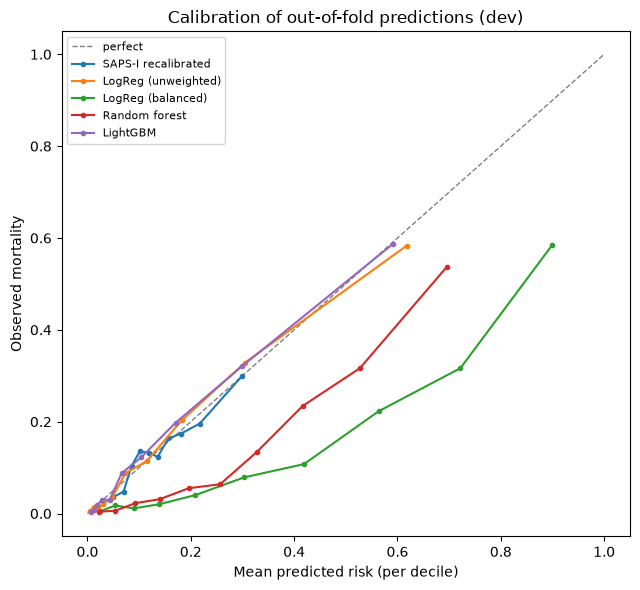

,model,mean predicted,observed,Brier
0,SAPS-I recalibrated,0.1407,0.1407,0.1156
1,LogReg (unweighted),0.1407,0.1404,0.0868
2,LogReg (balanced),0.3422,0.1404,0.1451
3,Random forest,0.2728,0.1404,0.1139
4,LightGBM,0.1339,0.1404,0.0871


In [9]:
# ── Cell 9: calibration of the OOF probabilities ────────────────────
# INSIGHTS
# - Brier score = mean squared error of the probabilities (lower is better). It mixes
#   ranking and calibration.
# - Calibration curve: stays are grouped into 10 bins by predicted risk; observed
#   mortality per bin is plotted against mean predicted risk. Perfect = the diagonal.
# - class_weight="balanced" tells the model deaths are ~6x as common as they are, so
#   its probabilities come out far too high. Full calibration work is Phase 5.
# - Result: LogReg unweighted is well calibrated on average (mean predicted 14.07% vs
#   observed 14.04%, Brier 0.0868); LightGBM similar (13.4%, Brier 0.0871). The class-
#   weighted models are badly over-predicting: LogReg balanced mean 34.2% (Brier 0.145),
#   RF 27.3% (Brier 0.114). Same ranking, much worse probabilities.
prob_models = ["SAPS-I recalibrated", "LogReg (unweighted)", "LogReg (balanced)", "Random forest", "LightGBM"]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="perfect")
rows = []
for name in prob_models:
    ok = OOF[name].notna()
    frac, mean_pred = calibration_curve(y[ok], OOF[name][ok], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", ms=3, label=name)
    rows.append({"model": name, "mean predicted": OOF[name][ok].mean(), "observed": y[ok].mean(),
                 "Brier": ((OOF[name][ok] - y[ok]) ** 2).mean()})
ax.set_xlabel("Mean predicted risk (per decile)")
ax.set_ylabel("Observed mortality")
ax.set_title("Calibration of out-of-fold predictions (dev)")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES / "04_calibration_oof.png", dpi=150)
plt.show()
display(pd.DataFrame(rows).round(4))

In [10]:
# ── Cell 10: refit the final model on all dev data and save it ─────
# INSIGHTS
# - The hyperparameters are re-chosen with the same grid, now using the 5 saved folds
#   as the CV split (PredefinedSplit), then the model is refitted on all dev stays.
# - Saved: models/final_model.joblib (+ JSON with features, params, excluded stays)
#   and data/processed/oof_predictions.parquet for Phase 5.
# - Result: LogReg (unweighted) refitted on all 7,990 dev stays with C = 0.03
#   (CV AUPRC 0.556). The model file is tiny (0.02 MB). OOF predictions saved (7,990 x 12).
SPECS = {
    "LogReg (unweighted)": (M.make_logreg(FEATURES, class_weight=None), GRID_LR),
    "LogReg (balanced)": (M.make_logreg(FEATURES, class_weight="balanced"), GRID_LR),
    "Random forest": (M.make_rf(), GRID_RF),
    "LightGBM": (M.LGBMEarlyStopping(), GRID_GBM),
}
est, grid = SPECS[FINAL]
search = GridSearchCV(est, grid, scoring="average_precision", cv=PredefinedSplit(folds), n_jobs=1)
search.fit(X, y)
final_model = search.best_estimator_
print(f"{FINAL}: best params {search.best_params_}, CV AUPRC {search.best_score_:.3f}")

joblib.dump(final_model, MODELS / "final_model.joblib")
meta = {
    "model": FINAL, "params": {k: (v if isinstance(v, (int, float, str)) else str(v))
                               for k, v in search.best_params_.items()},
    "features": FEATURES, "n_train": int(len(dev)), "train_sets": ["a", "b"],
    "excluded_empty_stays_dev": dev_all.loc[empty, "RecordID"].astype(int).tolist(),
    "selection_rule": "best pooled OOF AUPRC; simplest model not significantly worse (paired bootstrap)",
}
(MODELS / "final_model.json").write_text(json.dumps(meta, indent=2))
size_mb = (MODELS / "final_model.joblib").stat().st_size / 1e6
print(f"Saved models/final_model.joblib ({size_mb:.2f} MB) and models/final_model.json")

oof_df = dev[["RecordID", "fold", M.LABEL, "SAPS-I", "SOFA"]].copy()
for name, p in OOF.items():
    oof_df[name] = p.values
oof_df.to_parquet(PROCESSED / "oof_predictions.parquet", index=False)
print("Saved data/processed/oof_predictions.parquet:", oof_df.shape)

LogReg (unweighted): best params {'model__C': 0.03}, CV AUPRC 0.556
Saved models/final_model.joblib (0.02 MB) and models/final_model.json
Saved data/processed/oof_predictions.parquet: (7990, 12)


In [11]:
# ── Cell 11: what does the final model rely on? (first look) ───────
# INSIGHTS
# - Logistic regression: standardised coefficients (effect of +1 SD on the log-odds).
#   Trees: LightGBM split gain / RF impurity importance. SHAP comes in Phase 5.
# - Result: GCS_last has by far the largest weight (-0.64: higher GCS, lower risk), then
#   Age +0.36, BUN_last +0.34, pH, ICU type cardiac surgery -0.23, HCO3_last -0.21.
#   Some signs look odd (GCS_min +0.34, Creatinine_max -0.25, MechVent_ever -0.25):
#   correlated features share and trade weight, so single coefficients should not be
#   read as causal effects. SHAP in Phase 5 gives a cleaner picture.
if FINAL.startswith("LogReg"):
    names = final_model[:-1].get_feature_names_out()
    coef = pd.Series(final_model[-1].coef_[0], index=names)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
    display(top.round(3).to_frame("coefficient (per SD)"))
else:
    imp = pd.Series(final_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
    display((imp / imp.sum()).head(15).round(4).to_frame("share of importance"))

,coefficient (per SD)
GCS_last,-0.640
Age,0.358
GCS_min,0.340
BUN_last,0.338
pH_mean,0.332
pH_min,-0.268
MechVent_ever,-0.253
GCS_mean,-0.250
BUN_min,0.248
Creatinine_max,-0.245


## Summary

- **Modeling set:** 7,990 dev stays (10 empty stays excluded, 0 deaths among them), 1,122 deaths, 225 features, the 5 saved folds, nested CV.
- **Results (pooled out-of-fold, 95% bootstrap CI):**

| Model | AUROC | AUPRC | Brier |
|---|---|---|---|
| Logistic regression (unweighted) | **0.867** [0.855, 0.877] | **0.550** [0.518, 0.581] | 0.0868 |
| Logistic regression (balanced) | 0.867 [0.856, 0.877] | 0.548 [0.516, 0.579] | 0.1451 |
| LightGBM | 0.866 [0.855, 0.877] | 0.547 [0.515, 0.577] | 0.0871 |
| Random forest | 0.850 [0.839, 0.862] | 0.494 [0.462, 0.525] | 0.1139 |
| SAPS-I (raw score) | 0.661 [0.643, 0.678] | 0.241 [0.220, 0.264] | - |
| SOFA (raw score) | 0.639 [0.622, 0.656] | 0.256 [0.234, 0.281] | - |

- **Final model (by the pre-stated rule): unweighted logistic regression**, C = 0.03. LightGBM is statistically tied with it, and random forest is significantly worse. With 8,000 stays and good summary features, a regularised linear model is as good as boosting, and it is simpler, faster and easier to explain.
- **Versus SAPS-I** (same 7,648 stays, paired bootstrap): +0.207 AUROC [+0.190, +0.224] and +0.310 AUPRC [+0.282, +0.338]. The model clearly beats the clinical score on the dev set.
- **Calibration:** the unweighted models are well calibrated on average (14.1% predicted vs 14.0% observed). Class weighting does not improve the ranking at all, but it inflates the probabilities (balanced LogReg predicts 34% on average), so we do not use it.
- **Caveats:** these are dev-set (cross-validation) numbers. The real test is set-c in Phase 5. LightGBM picked the smallest trees in the grid every time. Single logistic coefficients are not causal effects, because the features are correlated.
- **Saved:** `models/final_model.joblib` (0.02 MB), `models/final_model.json`, `data/processed/oof_predictions.parquet`, `reports/figures/04_calibration_oof.png`.

**Next:** `05_evaluation.ipynb`: score the final model once on set-c, plus calibration, threshold choice, subgroups (age, gender, ICU type), SHAP and leakage checks.